<a href="https://colab.research.google.com/github/RiyonTwinkle/ML/blob/main/Exp_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
data = pd.read_csv("auto-mpg.csv")
data.replace("?", np.nan, inplace=True)
data.dropna(inplace=True)
data["displacement"] = data["displacement"].astype(float)

In [3]:
X = data[["displacement"]]
y = data["mpg"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_r2 = r2_score(y_test, y_pred_linear)

In [6]:
poly2 = PolynomialFeatures(degree=2)
X_train_poly2 = poly2.fit_transform(X_train)
X_test_poly2 = poly2.transform(X_test)
poly_model2 = LinearRegression()
poly_model2.fit(X_train_poly2, y_train)
y_pred_poly2 = poly_model2.predict(X_test_poly2)
poly2_mse = mean_squared_error(y_test, y_pred_poly2)
poly2_r2 = r2_score(y_test, y_pred_poly2)

In [7]:
poly3 = PolynomialFeatures(degree=3)
X_train_poly3 = poly3.fit_transform(X_train)
X_test_poly3 = poly3.transform(X_test)
poly_model3 = LinearRegression()
poly_model3.fit(X_train_poly3, y_train)
y_pred_poly3 = poly_model3.predict(X_test_poly3)
poly3_mse = mean_squared_error(y_test, y_pred_poly3)
poly3_r2 = r2_score(y_test, y_pred_poly3)

In [8]:
comparison = pd.DataFrame({
    "Model":["Linear Regression","Polynomial Regression (Degree 2)","Polynomial Regression (Degree 3)"],
    "MSE":[round(linear_mse,2),round(poly2_mse,2),round(poly3_mse,2)],
    "R2 Score":[round(linear_r2,2),round(poly2_r2,2),round(poly3_r2,2)]
})

print(comparison)

                              Model    MSE  R2 Score
0                 Linear Regression  22.30      0.57
1  Polynomial Regression (Degree 2)  21.66      0.58
2  Polynomial Regression (Degree 3)  22.15      0.57


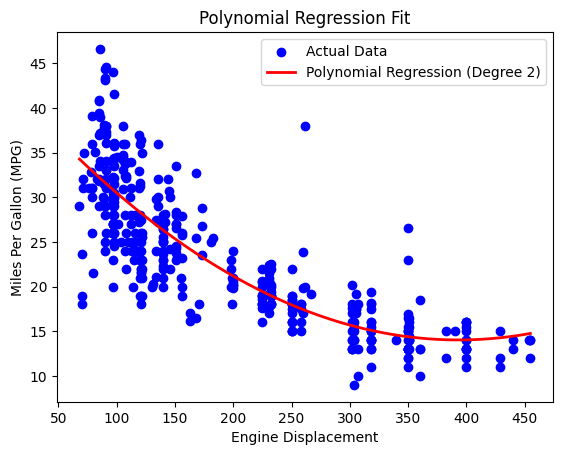

In [9]:
X_plot = pd.DataFrame(
    np.linspace(X["displacement"].min(), X["displacement"].max(),300),
    columns=["displacement"]
)

X_plot_poly = poly2.transform(X_plot)
y_plot = poly_model2.predict(X_plot_poly)

plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X_plot["displacement"], y_plot, color="red", linewidth=2,
         label="Polynomial Regression (Degree 2)")
plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon (MPG)")
plt.title("Polynomial Regression Fit")
plt.legend()
plt.show()